# 03: XGBoost on the validation split

Fits the first machine-learning model and compares it with the two baselines, on identical
cases and with the same scoring harness.

All the logic lives in `src/cyclone/`, and `docs/components.md` explains each module. This
notebook only calls it in order: load → features → fit → score → look at the result.

**The test split stays locked.** Test start times are counted to check the samples, but no
forecast is made for them here. Test scores happen once, at the end of Project 1.

**Running locally:** use the `cyclone` kernel after `pip install -e .`. Run notebook 01
first, because this one reads `ni_clean.parquet`. The first run needs internet, because
cartopy downloads the land file.

**Running on Colab:** run these in a first cell:

```python
!git clone https://github.com/Anshuman-Alok-Gupta/Cyclone_Project.git
!pip install -e Cyclone_Project
```

Then choose *Runtime → Restart session*, because Python only finds a newly installed
editable package when it starts. After the restart, run this before the cells below:

```python
from google.colab import drive
drive.mount("/content/drive")

import os
os.environ["CYCLONE_DATA_DIR"] = "/content/drive/MyDrive/cyclone-project/data"
```


In [1]:
import numpy as np
import pandas as pd

from cyclone import config, io, xgb_model
from cyclone.baselines import fit_cliper, persistence, predict_cliper
from cyclone.checks import check_dist_to_land, check_expected, check_samples
from cyclone.features import FEATURE_COLUMNS, build_features
from cyclone.plotting import plot_error_by_lead, plot_feature_importance, plot_forecasts
from cyclone.samples import make_init_times, make_truth
from cyclone.scoring import score, skill, summarize


## Load and build the inputs

The first `check_samples` confirms the start times are the verified ones. The second runs on
the feature table. If `build_features` had dropped a row anywhere, the same counts would no
longer match: train 2,515 / 1,869 / 1,324 and validation 438 / 340 / 256 at +24, +48 and
+72 h.


In [2]:
df = pd.read_parquet(config.ni_clean_path())
check_expected(df)

truth = make_truth(df)
init_times = make_init_times(df)
check_samples(init_times, truth)

features = build_features(init_times)
check_samples(features, truth)

same_rows = features[["SID", "init_time"]].equals(init_times[["SID", "init_time"]])
print(f"\n{len(FEATURE_COLUMNS)} inputs. Same rows in the same order as init_times: {same_rows}")


Counts match: 5,694 rows, 258 storms, 184/27/47 train/val/test.
Sample counts match: 4,678 init times.
  train 3,203 init times; cases +24 h 2,515, +48 h 1,869, +72 h 1,324
  val     542 init times; cases +24 h 438, +48 h 340, +72 h 256
  test    933 init times; cases +24 h 749, +48 h 578, +72 h 430


Sample counts match: 4,678 init times.
  train 3,203 init times; cases +24 h 2,515, +48 h 1,869, +72 h 1,324
  val     542 init times; cases +24 h 438, +48 h 340, +72 h 256
  test    933 init times; cases +24 h 749, +48 h 578, +72 h 430

19 inputs. Same rows in the same order as init_times: True


**Missing inputs.** XGBoost can take a blank value. When a tree splits on a column, it tries
sending the rows with a blank down each side, and keeps whichever fits better as that
split's default direction. So nothing needs filling in, and no row is lost.

The table below shows how little this matters here. The only blanks are the wind inputs for
24 start times, all in train and all in 1980, so no validation or test row ever takes a
default direction.


In [3]:
features.groupby("split")[FEATURE_COLUMNS].agg(lambda column: column.isna().sum()).T.query("train + val + test > 0")


split,test,train,val
wind,0,24,0
dwind_12h,0,24,0
dwind_24h,0,24,0


## Sanity check: distance to land

Distance to land is recomputed from JTWC's position. To check it against something outside
this project, it's compared with IBTrACS `DIST2LAND` on rows where the JTWC and combined
positions are within 10 km. `DIST2LAND` stays inside this check and never reaches a model.

The middle of the distribution agrees closely, and so does land itself. The 90th percentile
doesn't, and that's expected. `DIST2LAND` comes from a land mask that leaves out small
islands such as the Maldives, while Natural Earth's has them. Near the Maldives, `DIST2LAND`
says 908 km where Natural Earth land is 95 km away. Without islands under 5,000 km², the
agreement within 10 km rises from 63.5% to 92.7%. `docs/components.md` has the details.


In [4]:
raw = io.load_ibtracs(config.ibtracs_path("NI"))
check_dist_to_land(df, raw)
del raw  # only this check reads the raw table


Distance to land against DIST2LAND, on 2,645 of 5,694 rows with the JTWC and combined positions within 10 km:
  median gap 5.1 km, 90th percentile 343 km
  within 10 km: 63.5%, within 25 km: 66.2%
  over land: 376 rows in both, of 383 here and 383 in IBTrACS


## Fit, and pick the settings

Six models are fitted, one per lead time and component. Each predicts the change in position
from t0, as CLIPER does.

`search` tries 20 combinations of settings, chosen at random from 180. For each one:

- **Tree depth** (`max_depth`): how many questions a tree can ask in a row.
- **Learning rate** (`learning_rate`): how much of its correction each tree applies.
- **Minimum samples per leaf** (`min_child_weight`): the fewest storm moments allowed at the
  end of a chain of questions, which stops a tree building a rule around one storm.
- **Subsampling** (`subsample`): the share of rows each tree sees.
- **Number of trees:** not searched. Each model keeps adding trees until its validation error
  has stopped improving for 50 trees, then goes back to its best point. This is
  *early stopping*.

The combination with the lowest validation error wins, and it's used for all six models.
Trees only ever learn from the train split. The random seed is fixed, so the same data on the
same device gives the same models.


In [5]:
device = xgb_model.pick_device()
xgb_models, search_table = xgb_model.search(features, truth, device=device)
search_table.round(3)


Searching 20 combinations on cpu


   1 of 20: {'subsample': 0.8, 'min_child_weight': 20, 'max_depth': 3, 'learning_rate': 0.02}


   2 of 20: {'subsample': 0.6, 'min_child_weight': 20, 'max_depth': 5, 'learning_rate': 0.02}


   3 of 20: {'subsample': 0.6, 'min_child_weight': 40, 'max_depth': 4, 'learning_rate': 0.1}


   4 of 20: {'subsample': 0.6, 'min_child_weight': 20, 'max_depth': 3, 'learning_rate': 0.05}


   5 of 20: {'subsample': 0.8, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.1}


... (12 outputs left out)

  18 of 20: {'subsample': 1.0, 'min_child_weight': 10, 'max_depth': 2, 'learning_rate': 0.1}


  19 of 20: {'subsample': 0.6, 'min_child_weight': 5, 'max_depth': 5, 'learning_rate': 0.05}


  20 of 20: {'subsample': 1.0, 'min_child_weight': 20, 'max_depth': 6, 'learning_rate': 0.02}


,subsample,min_child_weight,max_depth,learning_rate,km_24h,km_48h,km_72h,relative_error
0,0.6,40,4,0.05,118.763,275.354,422.364,1.007
1,0.6,20,3,0.05,119.915,269.855,429.942,1.009
2,0.6,40,2,0.05,119.732,272.255,429.140,1.011
3,0.6,40,4,0.10,120.018,274.883,425.978,1.013
4,0.8,20,3,0.02,120.593,277.840,423.898,1.016
5,0.6,10,3,0.02,120.306,274.468,430.808,1.017
6,0.6,40,5,0.02,120.622,274.371,430.295,1.017
7,0.8,40,3,0.10,120.261,276.184,429.530,1.018
8,0.6,5,4,0.02,120.194,278.169,430.789,1.021
9,0.8,10,3,0.02,120.658,278.627,428.530,1.021


The table is sorted best first. `relative_error` is each lead's error divided by the best any
combination reached at that lead, then averaged, so that 5% worse at 24 h counts the same as
5% worse at 72 h. The top combinations are close together, so the choice isn't critical.

The best settings are on the cautious side: a small share of rows per tree, and large leaves.
That fits a small, noisy dataset.

Below is how many trees early stopping kept. The longer leads stop sooner, because there's
less signal to find and fewer cases to learn from.


In [6]:
print(xgb_model.best_settings(search_table))
xgb_model.tree_counts(xgb_models)


{'max_depth': 4, 'learning_rate': 0.05, 'min_child_weight': 40, 'subsample': 0.6}


component,dlat,dlon
lead_h,,
24,122,120
48,56,94
72,45,74


**Why the validation score is optimistic.** Think of an exam where you sit 20 practice
papers on the same questions, then report your best mark. Some of that best mark is skill and
some is luck with those particular questions. Here, the 20 practice papers are the 20
combinations, and the questions are the validation storms. Early stopping has looked at the
same storms too. So the winning number flatters the model, and on these storms only.

CLIPER had no such help: it was fitted once on train and never saw validation. So the
comparison below leans in XGBoost's favour. The skill section measures by how much.

**Why the locked test set fixes this.** Test storms played no part in any of these choices, so
a model can't have been tuned to them. That only stays true if test is scored once, after
everything is fixed. If test scores were used to go back and change something, it would turn
into a second validation set, with the same problem.


## Save, and reload without retraining

The models are saved to the data directory, so a later notebook can load them. Reloading and
forecasting again must give exactly the same numbers.


In [7]:
xgb_model.save_models(xgb_models, search_table)
reloaded = xgb_model.load_models()

val_features = features[features["split"] == "val"]
same_forecasts = xgb_model.predict_xgboost(xgb_models, val_features).equals(
    xgb_model.predict_xgboost(reloaded, val_features)
)
print(f"Reloaded models give identical forecasts: {same_forecasts}")


Saved 6 models to D:\Cyclone_proj\data\models\xgboost


Reloaded models give identical forecasts: True


## Score all three models

The baselines are run as in notebook 02. All three forecast every validation start time at
every lead time, so the comparison is on identical cases, and the summary confirms it.


In [8]:
val = init_times[init_times["split"] == "val"]

cliper_models = fit_cliper(init_times, truth)
forecasts = pd.concat(
    [
        persistence(val),
        predict_cliper(cliper_models, val),
        xgb_model.predict_xgboost(xgb_models, val_features),
    ],
    ignore_index=True,
)

scored = score(forecasts, truth)
summary = summarize(scored, homogeneous=True)
summary.round(1)


CLIPER +24 h: fitted on 2,515 train cases
CLIPER +48 h: fitted on 1,869 train cases
CLIPER +72 h: fitted on 1,324 train cases


cliper: scored 1,034 of 1,626 forecasts; 592 had no matching truth
persistence: scored 1,034 of 1,626 forecasts; 592 had no matching truth
xgboost: scored 1,034 of 1,626 forecasts; 592 had no matching truth
Homogeneous comparison: kept 3,102 of 3,102 scored forecasts, the cases all 3 models have.


,model,lead_h,count,mean_km,median_km
0,cliper,24,438,129.0,118.4
1,cliper,48,340,289.0,267.0
2,cliper,72,256,459.1,423.7
3,persistence,24,438,137.6,123.6
4,persistence,48,340,319.7,281.9
5,persistence,72,256,509.8,468.6
6,xgboost,24,438,118.8,106.6
7,xgboost,48,340,275.4,258.5
8,xgboost,72,256,422.4,402.9


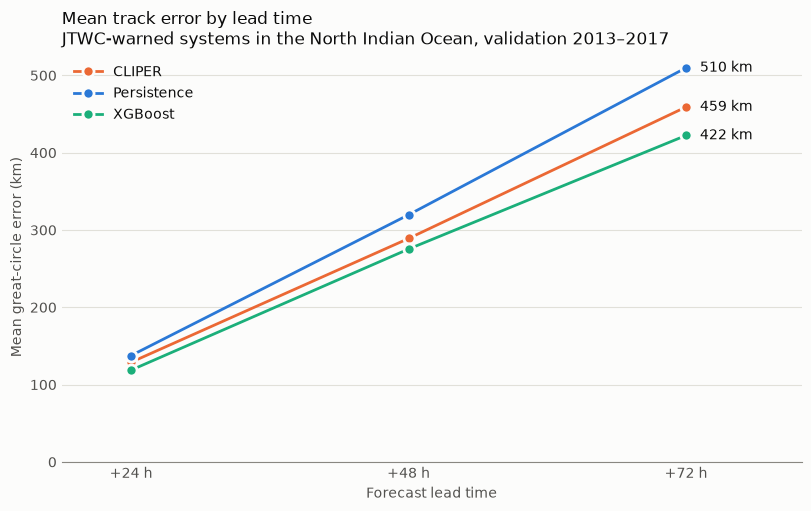

In [9]:
plot_error_by_lead(
    summary,
    title="Mean track error by lead time\n"
    "JTWC-warned systems in the North Indian Ocean, validation 2013–2017",
);


## Skill against CLIPER

Skill is the percentage improvement in mean error: 10 means a mean error 10% smaller than
CLIPER's.


In [10]:
skill(summary, reference="cliper").round(1)


model,persistence,xgboost
lead_h,,
24,-6.7,7.9
48,-10.6,4.7
72,-11.0,8.0


XGBoost beats CLIPER at every lead time, by 8% at +24 h, 5% at +48 h and 8% at +72 h. There are
two reasons not to take those numbers at face value.

**Few storms.** The 438 cases at +24 h come from only 26 storms, and fixes from one storm are
closely related. So a one-off test, recorded in `docs/components.md`, resampled whole storms
4,000 times to see how far the skill moves. 90% of the results fell in these ranges:

| Lead time | Skill | 90% range |
|---:|---:|---:|
| +24 h | 7.9% | 4.3 to 11.2% |
| +48 h | 4.7% | −1.5 to 10.3% |
| +72 h | 8.0% | −1.6 to 16.7% |

Only +24 h is clearly above zero. At +48 and +72 h, the storms alone could account for the gap.

**Choosing on the same storms.** As explained above, picking settings on validation flatters the
winner. To measure that, another one-off test picked settings on half the validation storms and
scored the other half, four times over. On the storms used for picking, the skill was
8.4%, 7.2% and 9.1%. On the fresh half it was 5.6%, 0.0% and 2.9%. So the effect isn't small here,
and much of the skill at +48 and +72 h may not carry over to new storms. The fresh numbers lean a
little low, because only half the storms guided the choice and the early stopping.

So the fair summary is: XGBoost looks better than CLIPER at +24 h, while at +48 and +72 h any lead
may be small or nothing. The test split will give the fair number.


## Overfitting check

A model *overfits* when it memorizes its training storms rather than learning rules that carry
over, a bit like a student who memorizes past answers and can't handle a new question. The
sign is a much lower error on the storms it trained on than on storms it has never seen.

Some gap is normal, and validation storms can also just be easier or harder than train
storms. So CLIPER is included as a reference. It's a straight-line fit that can hardly
memorize anything, so most of its gap comes from which storms are in each split.


In [11]:
train = init_times[init_times["split"] == "train"]
train_features = features[features["split"] == "train"]

train_scored = score(
    pd.concat(
        [predict_cliper(cliper_models, train), xgb_model.predict_xgboost(xgb_models, train_features)],
        ignore_index=True,
    ),
    truth,
)
train_summary = summarize(train_scored, homogeneous=True)

both = pd.concat(
    [train_summary.assign(split="train"), summary.assign(split="val")], ignore_index=True
)
both = both[both["model"] != "persistence"]
overfit = both.pivot(index=["model", "lead_h"], columns="split", values="mean_km")
overfit["val / train"] = overfit["val"] / overfit["train"]
overfit.round(2)


cliper: scored 5,708 of 9,609 forecasts; 3,901 had no matching truth
xgboost: scored 5,708 of 9,609 forecasts; 3,901 had no matching truth
Homogeneous comparison: kept 11,416 of 11,416 scored forecasts, the cases all 2 models have.


split            train     val  val / train
model   lead_h                             
cliper  24      145.50  128.95         0.89
        48      323.35  289.04         0.89
        72      485.20  459.14         0.95
xgboost 24      112.48  118.76         1.06
        48      248.22  275.35         1.11
        72      373.20  422.36         1.13

XGBoost's error is 6 to 13% higher on validation than on train. On its own that looks mild, but
CLIPER shows the validation storms were easier: its error is 5 to 11% *lower* there. Allowing for
that, XGBoost's gap is closer to 20%.

Another way to see it: on train, XGBoost's error is about 23% below CLIPER's, but on validation
only 5 to 8%. So most of its apparent lead on train storms doesn't carry over to new storms.

That's real overfitting, but moderate, and expected from a flexible model on a small dataset.
What matters is that it still does better than CLIPER on storms it never trained on. Early
stopping and large leaves are what keep the gap at this size.


## Which inputs did XGBoost rely on most?

*Gain* adds up how much each split on an input reduced a tree's error. The chart shows each
input's share, averaged over the six models, and the table splits it by lead time.


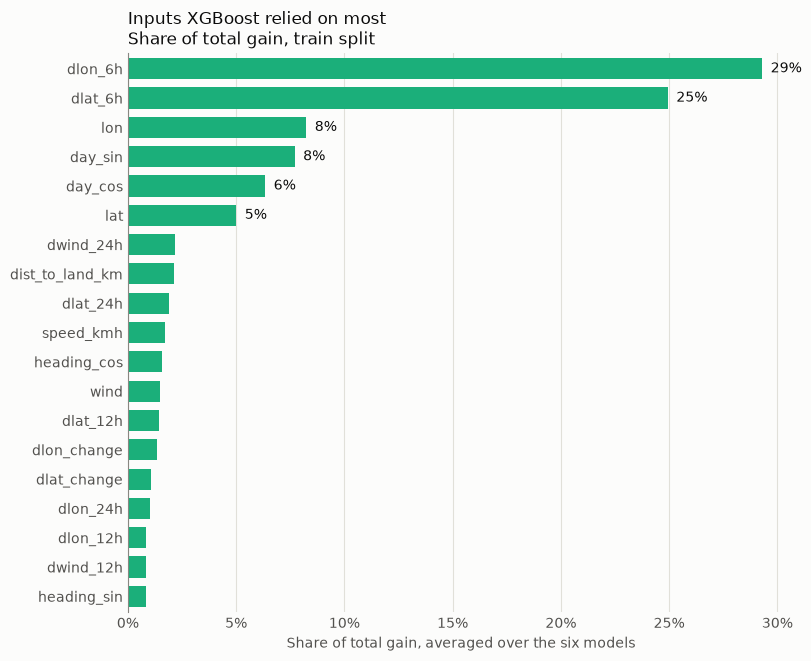

In [12]:
shares = xgb_model.gain_shares(xgb_models)
plot_feature_importance(shares, title="Inputs XGBoost relied on most\nShare of total gain, train split");


In [13]:
shares.round(3)


,+24 h,+48 h,+72 h,mean
dlon_6h,0.412,0.291,0.177,0.293
dlat_6h,0.340,0.251,0.158,0.250
lon,0.039,0.087,0.122,0.083
day_sin,0.022,0.073,0.137,0.077
day_cos,0.027,0.056,0.107,0.064
lat,0.024,0.050,0.077,0.050
dwind_24h,0.013,0.027,0.026,0.022
dist_to_land_km,0.013,0.027,0.024,0.022
dlat_24h,0.014,0.023,0.020,0.019
speed_kmh,0.018,0.017,0.016,0.017


The pattern changes sensibly with range. At +24 h, the last 6 h of motion takes 75% of the gain:
in the short term, a storm mostly keeps doing what it's doing. At +72 h that falls to 34%, and
position and time of year rise from 11% to 44%, because where a storm goes in three days depends
more on where it is and what season it is.

**How to read this with care:**

- **A big share doesn't mean an input is needed, and a small share doesn't mean it's useless.**
  The 6, 12 and 24 h motion inputs overlap heavily. When several inputs say nearly the same thing,
  the trees use whichever is slightly better at each split, and the others get little credit.
- **Gain is measured on the training storms.** It says how the trees were built, not what helps on
  new storms.
- **It isn't cause and effect.** Day of year doesn't steer a storm. It stands in for whatever
  changes with the seasons, such as the large-scale winds.

The first point can be tested. The cell below blanks some inputs, refits with the same settings,
and scores on validation. This is only a check, and no choice was made from it.


In [14]:
def error_without(blanked: list[str]) -> pd.Series:
    """Refit with some inputs blanked out, and return the mean validation error."""
    reduced = features.assign(**{column: np.nan for column in blanked})
    models = xgb_model.fit_models(reduced, truth, xgb_model.best_settings(search_table), device)
    reduced_val = reduced[reduced["split"] == "val"]
    return summarize(score(xgb_model.predict_xgboost(models, reduced_val), truth)).set_index("lead_h")["mean_km"]


six_hour_motion = ["dlat_6h", "dlon_6h"]
all_motion = [column for column in FEATURE_COLUMNS if column.startswith(("dlat", "dlon", "speed", "heading"))]

comparison = pd.DataFrame(
    {
        "all inputs": summary[summary["model"] == "xgboost"].set_index("lead_h")["mean_km"],
        "without 6 h motion": error_without(six_hour_motion),
        "without any motion": error_without(all_motion),
    }
)
comparison.round(1)


xgboost: scored 1,034 of 1,626 forecasts; 592 had no matching truth
Homogeneous comparison: kept 1,034 of 1,034 scored forecasts, the cases all 1 models have.


xgboost: scored 1,034 of 1,626 forecasts; 592 had no matching truth
Homogeneous comparison: kept 1,034 of 1,034 scored forecasts, the cases all 1 models have.


,all inputs,without 6 h motion,without any motion
lead_h,,,
24,118.8,125.2,205.6
48,275.4,278.6,391.9
72,422.4,430.4,542.7


Blanking the two inputs that hold 54% of the gain costs only 3 to 8 km, because the 12 and 24 h
windows carry nearly the same information. Blanking all motion costs 87 to 120 km. So motion
matters a great deal as a group, and no single window is essential.

Inputs are safer to read in groups like this than one bar at a time.


## Two storms on the map

One forecast is an illustration, not evidence: the tables above are the result. These maps
show what the numbers look like for a single storm.

On each map, a coloured line has up to three dots: the forecast at +24, +48 and +72 h, in that
order from the start. Compare each one with the labelled black dot for the same lead time.

### Cyclone Hudhud, 2014

Hudhud crossed the Bay of Bengal and hit Visakhapatnam on 12 October 2014. This is the same
start as in notebook 02, which was fixed before any error was seen. CLIPER did well here.


model,cliper,persistence,xgboost
lead_h,,,
24,29.8,99.4,29.3
48,76.6,164.0,108.9
72,109.3,274.4,172.6


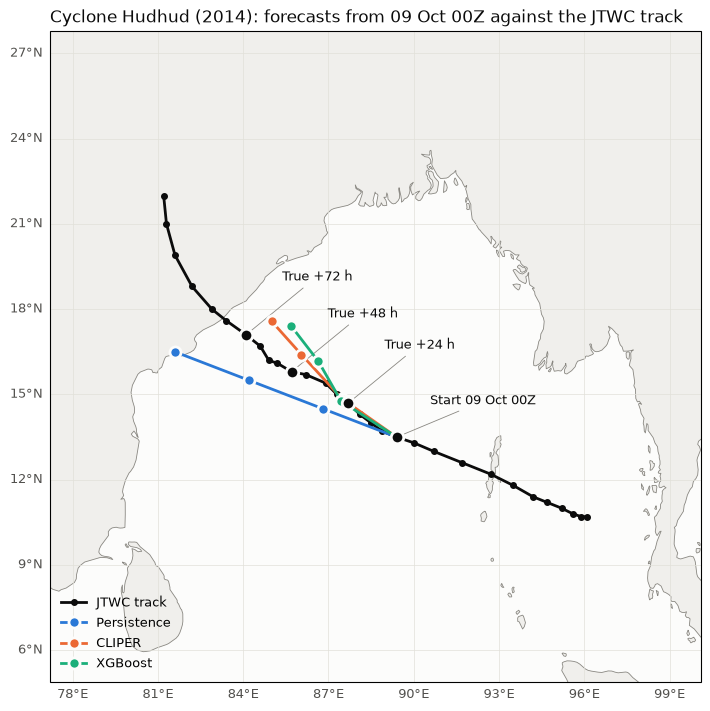

In [15]:
def errors_from(sid: str, start: pd.Timestamp) -> pd.DataFrame:
    """Return each model's error in km for one storm and start time."""
    rows = scored[(scored["SID"] == sid) & (scored["init_time"] == start)]
    return rows.pivot(index="lead_h", columns="model", values="error_km").round(1)


hudhud_sid = df[(df["NAME"] == "HUDHUD") & (df["SEASON"] == 2014)]["SID"].iloc[0]
hudhud_start = pd.Timestamp("2014-10-09 00:00")

plot_forecasts(
    truth,
    forecasts,
    sid=hudhud_sid,
    init_time=hudhud_start,
    title="Cyclone Hudhud (2014): forecasts from 09 Oct 00Z against the JTWC track",
);
errors_from(hudhud_sid, hudhud_start)


XGBoost matches CLIPER at +24 h, then falls behind it at +48 and +72 h. Both forecasts lag the
storm's run to the west, and XGBoost's lags more. This is one forecast from a storm where CLIPER
happened to do very well, and it doesn't change the averages above. Both are well ahead of
persistence, which can only continue a straight line.


### Cyclone Nanauk, 2014

Nanauk is a different kind of pick, chosen for being CLIPER's worst 24 h miss on the validation
split. The start time is found from the scores below, not typed in. Because it's the worst
case, it says nothing about how good XGBoost is on average. It's here to show what a hard
storm looks like.


CLIPER's worst 24 h miss: NANAUK, from 09 Jun 2014 18Z, 485 km


model,cliper,persistence,xgboost
lead_h,,,
24,485.0,491.4,371.1
48,875.6,1011.6,502.7
72,1114.0,1484.4,502.9


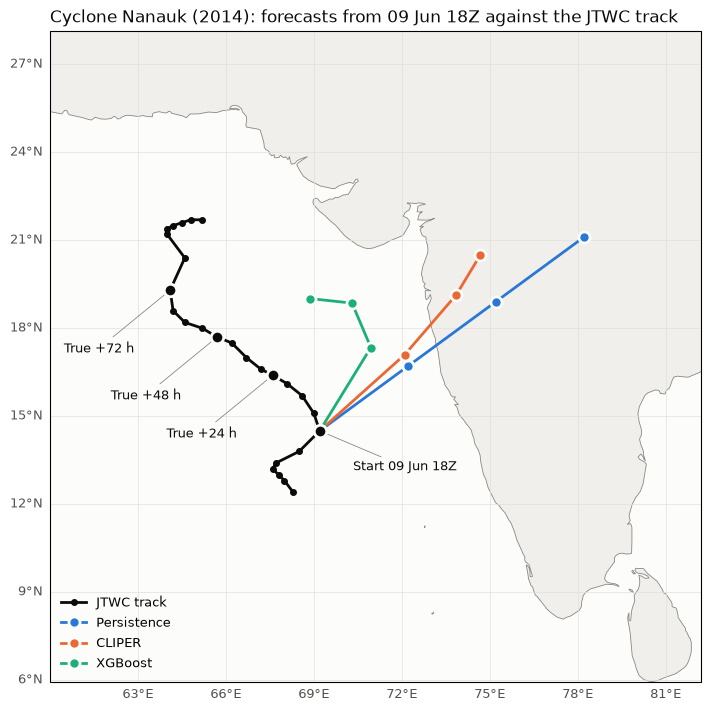

In [16]:
cliper_24h = scored[(scored["model"] == "cliper") & (scored["lead_h"] == 24)]
worst = cliper_24h.loc[cliper_24h["error_km"].idxmax()]
nanauk_sid, nanauk_start = worst["SID"], worst["init_time"]
print(
    f"CLIPER's worst 24 h miss: {df.loc[df['SID'] == nanauk_sid, 'NAME'].iloc[0]}, "
    f"from {nanauk_start:%d %b %Y %H}Z, {worst['error_km']:.0f} km"
)

plot_forecasts(
    truth,
    forecasts,
    sid=nanauk_sid,
    init_time=nanauk_start,
    title=f"Cyclone Nanauk (2014): forecasts from {nanauk_start:%d %b %H}Z against the JTWC track",
    labels_below=True,  # the forecasts run through the space above the track
);
errors_from(nanauk_sid, nanauk_start)


The storm had been moving north-east. Persistence and CLIPER carry that on towards India, but it
turned north-west instead. XGBoost turns too, and halves CLIPER's error by +72 h, yet it's still
more than 370 km out at every lead time.

Remember why this storm is here: the case was chosen for being CLIPER's worst, so XGBoost looks
better here than it would on a typical case. It's the kind of miss to expect from any model that
only sees a storm's own past. None of these models knows about the winds around the storm, which
is the information the AI weather models in Project 3 work from.
